In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from telegram_scraper import study, viz
from telegram_scraper.study import CHANNELS, CHANNEL_ORDER, SHORT_NAMES, WINDOW
from telegram_scraper.analysis import stats

viz.apply_style()
np.random.seed(study.SEED)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
posts = study.load_posts()
events = study.verified_events(posts)
f"{len(posts):,} posts from {posts['channel_slug'].nunique()} channels, {posts['timestamp'].min():%Y-%m-%d} to {posts['timestamp'].max():%Y-%m-%d}"

'12,221 posts from 6 channels, 2026-02-28 to 2026-04-17'

# 05 · Tone: can off-the-shelf classifiers say whether the channels converge?

> **Question.** Do state and private channels sound alike (the first pass claimed "fear-dominant convergence"), and can off-the-shelf tone classifiers be trusted to say so?
>
> **Answer.** No: against a blind second coder (an LLM, not ground truth) the sentiment and emotion labels reach only kappa 0.23 and 0.24, far below the 0.6 bar, because the classifiers call 57% of posts neutral and 4% positive where the coder calls 21% neutral and 26% positive (IDF 45%, Press TV 33% coder-positive); no tone comparison, "convergence" or "fear-dominant" statement is reportable, and the main result of this notebook is the disagreement itself.

## 0. Read this first: what these scores are, and what the validation found

Tone is measured with two off-the-shelf classifiers run on each post's cleaned text: **cardiffnlp/twitter-roberta-base-sentiment-latest** (negative / neutral / positive, summarised as `sentiment_score` = P(positive) - P(negative), range -1...+1) and **j-hartmann/emotion-english-distilroberta-base** (anger, disgust, fear, joy, neutral, sadness, surprise). Both were trained on social-media or general text, **not on war reporting**.

Section 2 tests them against a blind second coder on 900 posts (150 per channel). The second coder is **an LLM, not a human** (three Claude Sonnet sub-agents), so the test measures agreement with another automated reader and the coder is **not ground truth**. The result is a failure: **neither label reaches kappa 0.6** (sentiment 0.23, emotion 0.24). Sections 3-6 therefore print the model scores as computed (so the numbers can be inspected and, if the models are replaced, regenerated), but every figure is tagged as model output that failed validation and **none of it may be reported as a finding about the channels' tone**.

## 1. Score every post (cached)

In [2]:
tone = study.score_tone_cached(posts)
scored = posts.join(tone)
scored = scored[scored["sentiment_score"].notna()].reset_index(drop=True)
print(f"{len(scored):,} of {len(posts):,} posts have text to score")
scored.groupby("channel_slug").size().reindex(CHANNEL_ORDER).rename("scored_posts").to_frame().T

11,956 of 12,221 posts have text to score


channel_slug,presstv,irna-en,idfofficial,iltvnews,thetimesofisrael2022,jewishbreakingnewstelegram
scored_posts,6619,1635,1425,542,622,1113


## 2. Validation first: blind coding sheet and agreement with a second coder

`make_coding_sheet` draws up to 150 posts per channel (900 in total), shuffles them across channels so ids carry no channel information, and writes a **blind** sheet (`id`, `text`, empty `human_sentiment` / `human_emotion` columns) plus a private key holding the model's labels. The sheet is written once; if it already exists it is left alone so ids stay stable. The coded columns were filled by **an LLM, not a human**: three Claude Sonnet sub-agents (300 posts each) who never saw the key or the channel and judged mostly from the first 250-300 characters of each post (`data/validation/README.md`). That makes the "human_*" columns a second *model's* reading. It is a useful independent check, but it is **not ground truth** either. Cohen's kappa is computed per label; a label may be interpreted only if kappa >= 0.6. The result comes before the tone sections so every later figure can be read against it.

In [3]:
from telegram_scraper.analysis import validation
VAL_DIR = study.VALIDATION_DIR
SHEET, KEY, CODED = VAL_DIR / "coding_sheet.csv", VAL_DIR / "coding_sheet_key.csv", VAL_DIR / "coding_sheet_coded.csv"
if not SHEET.exists():
    sheet_df, key_df = validation.make_coding_sheet(
        scored, label_cols={"sentiment": "dominant_sentiment", "emotion": "dominant_emotion"},
        out_path=SHEET, key_path=KEY, n_per_group=150, group_col="channel_slug", text_col="clean_text", seed=study.SEED)
else:
    sheet_df, key_df = pd.read_csv(SHEET, dtype=str, keep_default_na=False, encoding="utf-8-sig"), pd.read_csv(KEY, dtype=str, keep_default_na=False, encoding="utf-8-sig")
print(f"sheet: {len(sheet_df)} rows -> {SHEET.relative_to(study.ROOT)}; private key -> {KEY.relative_to(study.ROOT)}")
print("rows per channel in the key:", key_df["channel"].value_counts().rename(SHORT_NAMES).to_dict())

sheet: 900 rows -> data/validation/coding_sheet.csv; private key -> data/validation/coding_sheet_key.csv
rows per channel in the key: {'IDF': 150, 'ToI': 150, 'ILTV': 150, 'JBN': 150, 'Press TV': 150, 'IRNA': 150}


In [4]:
agreement, usable = None, []
if CODED.exists():
    agreement = validation.score_agreement(CODED, KEY)
    usable = validation.usable_labels(agreement)
    show_cols = [c for c in agreement.columns if c != "confusion"]
    display(agreement[show_cols].round(3).T)
    print("labels with kappa >=", validation.KAPPA_THRESHOLD, ":", usable)
else:
    print("pending second coder: data/validation/coding_sheet_coded.csv does not exist yet.")
    print("The second coder will be an LLM (not a human) filling human_sentiment / human_emotion blind to channel.")

# Short phrases reused in every later figure subtitle / headline.
if agreement is None:
    VAL_NOTE, FLAG = "Unvalidated model output", "unvalidated"
else:
    kap = agreement.set_index("label")["kappa"]
    status = "passed" if len(usable) == 2 else ("failed" if not usable else "partly passed")
    VAL_NOTE = f"Model output that {status} validation (kappa: sentiment {kap['sentiment']:.2f}, emotion {kap['emotion']:.2f}; 0.6 needed)"
    FLAG = {"passed": "validated", "failed": "validation failed", "partly passed": "partly validated"}[status]
print(VAL_NOTE)

,0,1
label,sentiment,emotion
n,900,900
agreement,0.488,0.372
kappa,0.226,0.238
n_idfofficial,150,150
kappa_idfofficial,-0.016,-0.07
n_iltvnews,150,150
kappa_iltvnews,0.288,0.29
n_irna-en,150,150
kappa_irna-en,0.25,0.299


labels with kappa >= 0.6 : []
Model output that failed validation (kappa: sentiment 0.23, emotion 0.24; 0.6 needed)


In [5]:
# Where do the model and the second coder disagree? Label shares per channel, coder vs model.
if agreement is not None:
    coded = pd.read_csv(CODED, dtype=str, keep_default_na=False, encoding="utf-8-sig").drop(columns=["channel"], errors="ignore")
    pair = coded.merge(key_df, on="id", validate="one_to_one")
    for col in ("human_sentiment", "human_emotion", "model_sentiment", "model_emotion"):
        pair[col] = pair[col].str.strip().str.lower()
    rows = []
    for scale in ("sentiment", "emotion"):
        for who, col in (("LLM coder", f"human_{scale}"), ("model", f"model_{scale}")):
            t = pd.crosstab(pair["channel"], pair[col], normalize="index")
            t = t.reindex(CHANNEL_ORDER).stack().rename("share").reset_index()
            t.columns = ["channel_slug", "label", "share"]; t["scale"] = scale; t["rater"] = who
            rows.append(t)
    val_shares = pd.concat(rows, ignore_index=True)
    sent_cmp = val_shares[val_shares["scale"] == "sentiment"].pivot_table(index="channel_slug", columns=["rater", "label"], values="share").reindex(CHANNEL_ORDER)
    sent_cmp.index = [SHORT_NAMES[s] for s in sent_cmp.index]
    display((sent_cmp * 100).round(0).astype(int))
    overall = {scale: {rater: pair[f"{pre}_{scale}"].value_counts(normalize=True).round(3).to_dict() for rater, pre in (("LLM coder", "human"), ("model", "model"))} for scale in ("sentiment", "emotion")}
    print("overall sentiment shares:", overall["sentiment"])
    print("overall emotion shares:  ", overall["emotion"])

rater    LLM coder                     model                 
label     negative neutral positive negative neutral positive
Press TV        54      13       33       46      49        5
IRNA            69      11       20       41      53        7
IDF             35      20       45       18      80        2
ILTV            55      29       16       41      57        3
ToI             51      34       15       48      49        3
JBN             53      19       28       43      52        5

overall sentiment shares: {'LLM coder': {'negative': 0.529, 'positive': 0.261, 'neutral': 0.21}, 'model': {'neutral': 0.566, 'negative': 0.394, 'positive': 0.04}}
overall emotion shares:   {'LLM coder': {'joy': 0.253, 'neutral': 0.207, 'fear': 0.203, 'anger': 0.173, 'sadness': 0.118, 'surprise': 0.024, 'disgust': 0.021}, 'model': {'fear': 0.317, 'neutral': 0.281, 'anger': 0.168, 'sadness': 0.112, 'disgust': 0.071, 'joy': 0.038, 'surprise': 0.013}}


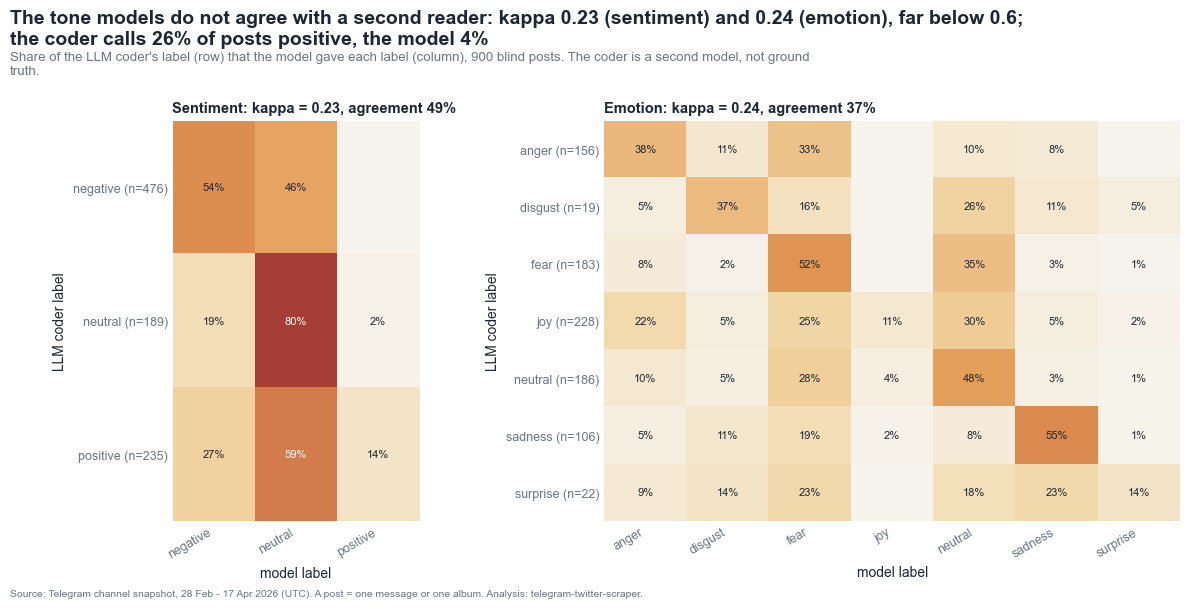

In [6]:
# Figure: row-normalised confusion matrices (rows = LLM coder, columns = model).
if agreement is not None:
    ag = agreement.set_index("label")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [3, 7], "wspace": 0.45})
    tidy = []
    for ax, scale, order in zip(axes, ("sentiment", "emotion"), (["negative", "neutral", "positive"], ["anger", "disgust", "fear", "joy", "neutral", "sadness", "surprise"])):
        cm = ag.loc[scale, "confusion"]
        order = [o for o in order if o in cm.index or o in cm.columns]
        cm = cm.reindex(index=order, columns=order, fill_value=0)
        norm = cm.div(cm.sum(axis=1).replace(0, np.nan), axis=0)
        shown = norm.copy(); shown.index = [f"{lab} (n={int(cm.loc[lab].sum())})" for lab in order]
        viz.annotated_heatmap(ax, shown, fmt="{:.0%}", vmin=0, vmax=1, min_label=0.005, rotate=30)
        ax.set_title(f"{scale.capitalize()}: kappa = {ag.loc[scale, 'kappa']:.2f}, agreement {ag.loc[scale, 'agreement']:.0%}", fontsize=10.5)
        ax.set_xlabel("model label"); ax.set_ylabel("LLM coder label")
        for r in order:
            for c in order:
                tidy.append({"scale": scale, "coder_label": r, "model_label": c, "n": int(cm.loc[r, c]), "row_share": float(norm.loc[r, c]) if r in norm.index else np.nan, "kappa": float(ag.loc[scale, "kappa"]), "agreement": float(ag.loc[scale, "agreement"])})
    sc = ag.loc["sentiment", "confusion"]
    model_pos = float(sc["positive"].sum() / sc.to_numpy().sum()) if "positive" in sc.columns else 0.0
    coder_pos = float(sc.loc["positive"].sum() / sc.to_numpy().sum()) if "positive" in sc.index else 0.0
    viz.headline(fig, f"The tone models do not agree with a second reader: kappa {ag.loc['sentiment', 'kappa']:.2f} (sentiment) and {ag.loc['emotion', 'kappa']:.2f} (emotion), far below 0.6; the coder calls {coder_pos:.0%} of posts positive, the model {model_pos:.0%}",
                 "Share of the LLM coder's label (row) that the model gave each label (column), 900 blind posts. The coder is a second model, not ground truth.", y=1.02, wrap=110)
    viz.done(fig, "05_validation_confusion", pd.DataFrame(tidy))

In [7]:
# What do the disagreements look like? Posts the coder called positive that the model called neutral or negative (random, seed 42).
if agreement is not None:
    texts = sheet_df.set_index("id")["text"]
    miss = pair[(pair["human_sentiment"] == "positive") & pair["model_sentiment"].isin(["neutral", "negative"])]
    print(f"{len(miss)} of {int((pair['human_sentiment'] == 'positive').sum())} coder-positive posts were scored neutral/negative by the model "
          f"({(miss['model_sentiment'] == 'neutral').mean():.0%} of those neutral)")
    for slug in ("idfofficial", "presstv", "irna-en", "iltvnews"):
        sub = miss[miss["channel"] == slug]
        print("=" * 100); print(f"{SHORT_NAMES[slug]}: {len(sub)} such posts; 3 examples (coder positive/{'/'.join(sorted(set(sub['human_emotion'])))[:40]}; model labels shown)")
        for r in sub.sample(min(3, len(sub)), random_state=study.SEED).itertuples():
            print(f"  [coder {r.human_sentiment}/{r.human_emotion} | model {r.model_sentiment}/{r.model_emotion}] {texts[r.id][:210]!r}")

203 of 235 coder-positive posts were scored neutral/negative by the model (68% of those neutral)
IDF: 64 such posts; 3 examples (coder positive/anger/joy; model labels shown)
  [coder positive/joy | model negative/fear] 'Today (Sunday), the IDF struck a crossing over the Litani River that was used by Hezbollah terrorists to maneuver from north to south of the Litani River in Lebanon.\n\nThe Hezbollah terrorist organization used t'
  [coder positive/joy | model neutral/neutral] 'The Chief of the General Staff Approves Plans for Continued Limited, Targeted Operations in the Northern Command: “The impact of the strike and the weakening of the radical regime in Iran is also being felt in '
  [coder positive/joy | model neutral/fear] 'The IDF struck a main IRGC headquarters established in civilian infrastructure\n\nAs part of a wave of strikes that was completed a short while ago in the heart of Tehran, the Israeli Air Force, guided by IDF int'
Press TV: 42 such posts; 3 examples (coder pos

**Reading the figures and examples.** Agreement is 49% for sentiment and 37% for emotion (kappa 0.23 and 0.24). The disagreement is systematic rather than random:

- *Sentiment.* On the same 900 posts the coder labels 53% negative, 26% positive and 21% neutral; the model labels 39% negative, 57% neutral and 4% positive. Of the 235 posts the coder calls positive, the model calls 59% neutral, 27% negative and only 14% positive; of the 476 the coder calls negative, the model calls 46% neutral. Neutral is the best-matched class (80% of coder-neutral posts are model-neutral).
- *By channel* (table above; about ±8 points at n = 150): the coder labels 45% of IDF posts positive, 33% of Press TV's, 28% of JBN's, 20% of IRNA's, 16% of ILTV's and 15% of ToI's, while the model labels only 2-7% of any channel positive and 49-80% neutral. The ranking of channels by negativity differs too: the coder's most negative channel is IRNA (69% negative) whereas the model labels only 41% of IRNA's posts negative, no more than ILTV (41%) and less than ToI (48%), Press TV (46%) and JBN (43%).
- *What the disagreements look like* (printed examples): the coder reads claims of success or defiance as positive or joyful, such as the IDF reporting strikes on Tehran and on a Litani crossing, a Press TV message to Trump ("YOU'RE FIRED") and a Leader's "conquer the peak" speech, IRNA's reports of Iranian missiles hitting Tel Aviv, and ILTV's good news about Ben-Gurion reopening, while the classifiers see strike-and-target vocabulary and score it neutral or negative (often "fear"). In war communiqués "positive" means favourable to the speaker's side, not pleasant words, and a classifier trained on product reviews and tweets cannot see that.
- *Emotion.* The coder's most common label is joy (25% of posts, n = 228) against 4% for the model; the model's most common is fear (32%) against 20% for the coder. When the coder says joy the model says neutral (30%), fear (25%), anger (22%) or joy (11%). The labels agree best where content is plainly distressing (coder sadness: 55% model sadness; coder fear: 52% model fear).

Two cautions on the coder: it judged mostly from the first 250-300 characters, so long IDF and IRNA posts were truncated; and counting triumphal or defiant claims as "positive/joy" is a codebook choice another coder could reject. The honest summary is that two automated readers define tone differently on propaganda-like text, not that one is right.

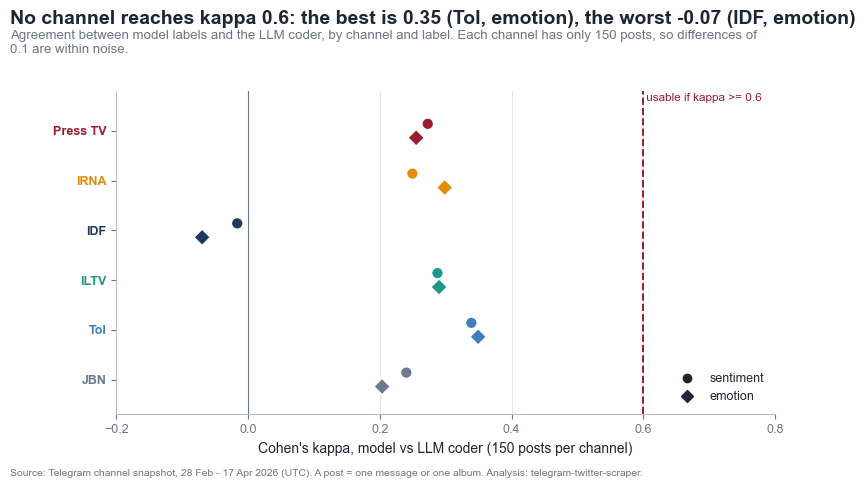

In [8]:
# Figure: per-channel kappa against the 0.6 usability threshold.
if agreement is not None:
    ag = agreement.set_index("label")
    krows = [{"channel_slug": s, "channel": SHORT_NAMES[s], "scale": scale, "kappa": float(ag.loc[scale, f"kappa_{s}"]), "n": int(ag.loc[scale, f"n_{s}"])} for s in CHANNEL_ORDER for scale in ("sentiment", "emotion")]
    kap_ch = pd.DataFrame(krows)
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    ypos = {s: len(CHANNEL_ORDER) - 1 - i for i, s in enumerate(CHANNEL_ORDER)}
    for scale, marker, dy in (("sentiment", "o", 0.14), ("emotion", "D", -0.14)):
        sub = kap_ch[kap_ch["scale"] == scale]
        ax.scatter(sub["kappa"], [ypos[s] + dy for s in sub["channel_slug"]], marker=marker, s=70, c=[viz.CHANNEL_COLORS[s] for s in sub["channel_slug"]], edgecolor="white", linewidth=1, zorder=3, label=scale)
    ax.axvline(validation.KAPPA_THRESHOLD, color=viz.ACCENT, lw=1.4, ls="--"); ax.text(validation.KAPPA_THRESHOLD, len(CHANNEL_ORDER) - 0.45, " usable if kappa >= 0.6", color=viz.ACCENT, fontsize=8.5, va="bottom")
    ax.axvline(0, color=viz.MUTED, lw=0.8); ax.set_xlim(-0.2, 0.8); ax.set_ylim(-0.7, len(CHANNEL_ORDER) - 0.2)
    ax.set_yticks(list(ypos.values())); ax.set_yticklabels([SHORT_NAMES[s] for s in ypos]); viz.color_channel_ticklabels(ax)
    ax.grid(axis="y", visible=False); ax.set_xlabel("Cohen's kappa, model vs LLM coder (150 posts per channel)")
    ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=viz.INK, label="sentiment"), plt.Line2D([], [], marker="D", ls="", color=viz.INK, label="emotion")], loc="lower right")
    best = kap_ch.sort_values("kappa").iloc[-1]; worst = kap_ch.sort_values("kappa").iloc[0]
    viz.headline(fig, f"No channel reaches kappa 0.6: the best is {best['kappa']:.2f} ({best['channel']}, {best['scale']}), the worst {worst['kappa']:.2f} ({worst['channel']}, {worst['scale']})",
                 "Agreement between model labels and the LLM coder, by channel and label. Each channel has only 150 posts, so differences of 0.1 are within noise.", y=1.03, wrap=100)
    viz.done(fig, "05_kappa_by_channel", kap_ch)

**Reading the figure.** All twelve per-channel kappas are between -0.07 and 0.35; none comes within 0.25 of the 0.6 threshold. The IDF is the extreme case (sentiment -0.02, emotion -0.07, i.e. chance agreement): its posts are communiqués that the coder labels positive 45% of the time and the model labels neutral 80% of the time. For the other five channels kappa is 0.20-0.35 and the ordering among them (ToI highest, JBN lowest) is within noise at 150 posts per channel. No channel's labels are usable on their own.

In [9]:
# Interpretation gate: only labels that clear kappa >= 0.6 may be interpreted.
if agreement is None:
    verdict = ("**Validation is pending.** Neither the sentiment nor the emotion labels have been checked against a second coder, "
               "so every tone result in this notebook is **exploratory model output** and must not be presented as a finding about the channels' real tone.")
else:
    lines = []
    for label in ("sentiment", "emotion"):
        k = float(agreement.loc[agreement["label"] == label, "kappa"].iloc[0])
        lines.append(f"- **{label}**: kappa = {k:.2f} -> " + ("usable (>= 0.6): comparisons may be interpreted." if label in usable else "**NOT usable (< 0.6): do not interpret comparisons of this label.**"))
    verdict = "\n".join(lines)
    if not usable:
        verdict += ("\n\n**Verdict: neither label passes.** Sections 3-6 below are therefore reported as model output that failed validation: "
                    "the means, label shares, TOST equivalence results and event timelines are *not* findings about the channels. "
                    "The second coder is itself an LLM and not ground truth, so this shows disagreement between two automated readers, not which one is right.")
display(Markdown(verdict))

- **sentiment**: kappa = 0.23 -> **NOT usable (< 0.6): do not interpret comparisons of this label.**
- **emotion**: kappa = 0.24 -> **NOT usable (< 0.6): do not interpret comparisons of this label.**

**Verdict: neither label passes.** Sections 3-6 below are therefore reported as model output that failed validation: the means, label shares, TOST equivalence results and event timelines are *not* findings about the channels. The second coder is itself an LLM and not ground truth, so this shows disagreement between two automated readers, not which one is right.

## 3. Average sentiment per channel (model output)

Mean `sentiment_score` per channel with a 95% percentile-bootstrap interval (5,000 resamples of posts). Sections 3-6 report model scores **as computed**, each flagged with the validation verdict from section 2; read them as a description of what the classifiers say, not of what the channels sound like.

,channel_slug,channel,n,mean,ci_low,ci_high
0,presstv,Press TV,6619,-0.350,-0.360,-0.341
1,irna-en,IRNA,1635,-0.234,-0.255,-0.213
2,idfofficial,IDF,1425,-0.157,-0.173,-0.141
3,iltvnews,ILTV,542,-0.308,-0.342,-0.275
4,thetimesofisrael2022,ToI,622,-0.347,-0.376,-0.320
5,jewishbreakingnewstelegram,JBN,1113,-0.305,-0.330,-0.281


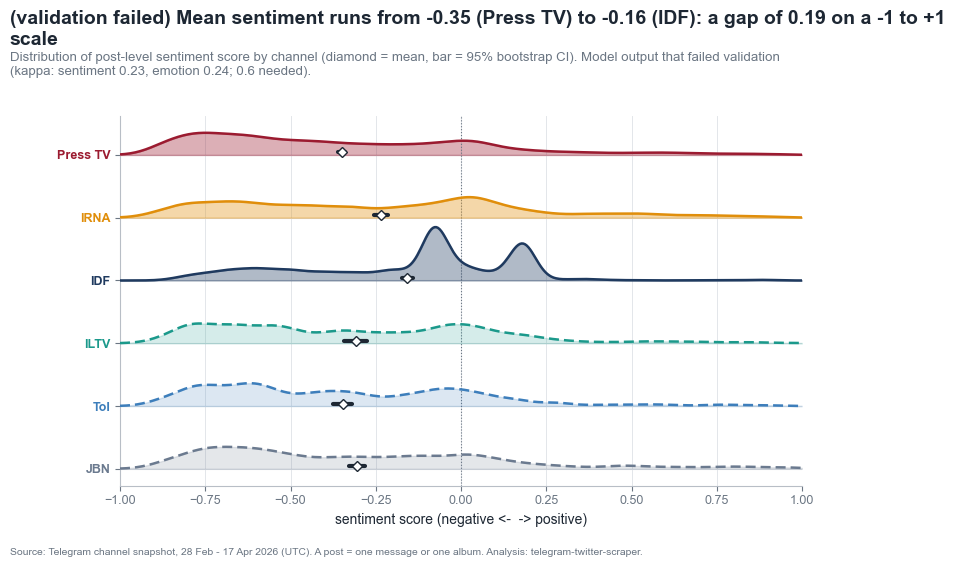

In [10]:
rows = []
for slug in CHANNEL_ORDER:
    r = stats.bootstrap_mean_ci(scored.loc[scored["channel_slug"] == slug, "sentiment_score"], n_boot=5000, seed=study.SEED)
    rows.append({"channel_slug": slug, "channel": SHORT_NAMES[slug], **r})
sent = pd.DataFrame(rows)
display(sent.round(3))

fig, ax = plt.subplots(figsize=(8.8, 4.8))
samples = {s: g["sentiment_score"] for s, g in scored.groupby("channel_slug")}
viz.ridgeline(ax, samples, xlim=(-1, 1), bw=0.12, means={r.channel_slug: (r.mean, r.ci_low, r.ci_high) for r in sent.itertuples()},
              xlabel="sentiment score (negative <-  -> positive)")
lo, hi = sent.sort_values("mean").iloc[0], sent.sort_values("mean").iloc[-1]
viz.headline(fig, f"({FLAG}) Mean sentiment runs from {lo['mean']:+.2f} ({lo['channel']}) to {hi['mean']:+.2f} ({hi['channel']}): a gap of {hi['mean'] - lo['mean']:.2f} on a -1 to +1 scale",
             "Distribution of post-level sentiment score by channel (diamond = mean, bar = 95% bootstrap CI). " + VAL_NOTE + ".")
viz.done(fig, "05_sentiment_ridgeline", sent)

**Reading the figure (model scores that failed validation; not a finding).** As computed, Press TV (-0.35; CI -0.36 to -0.34) and ToI (-0.35; -0.38 to -0.32) have the lowest mean score, then JBN (-0.31), ILTV (-0.31), IRNA (-0.23) and the IDF (-0.16). The distributions overlap heavily; the IDF's two sharp peaks near -0.08 and +0.18 are the repeated alert and all-clear templates. Section 2 says how little to read into these gaps: the classifier labels only 2-7% of any channel's posts positive while a second reader calls 15-45% positive, and the channels it under-rates most are exactly the ones with the most triumphal communiqués (IDF, Press TV). The gaps therefore partly measure how much success-claiming language a channel uses and how the classifier handles it, not how gloomy the channel is.

## 4. Label and emotion shares (model output)

The classifiers also assign each post a dominant label; the bars show shares per channel (Wilson 95% intervals are in the exported data).

label,negative,neutral,positive
channel_slug,,,
presstv,46.7,48.7,4.6
irna-en,35.1,58.1,6.8
idfofficial,20.9,78.3,0.8
iltvnews,42.8,53.5,3.7
thetimesofisrael2022,44.2,52.7,3.1
jewishbreakingnewstelegram,43.8,50.7,5.6


label,fear,anger,sadness,disgust,surprise,joy,neutral
channel_slug,,,,,,,
presstv,27.4,26.7,8.6,11.5,1.0,5.3,19.6
irna-en,19.6,29.2,12.4,8.9,0.7,10.2,19.1
idfofficial,29.2,11.3,2.2,1.7,0.1,0.4,55.2
iltvnews,31.0,17.2,14.0,7.9,0.2,3.3,26.4
thetimesofisrael2022,34.2,14.0,18.8,2.7,1.3,4.7,24.3
jewishbreakingnewstelegram,35.4,11.6,9.8,8.2,2.0,2.6,30.5


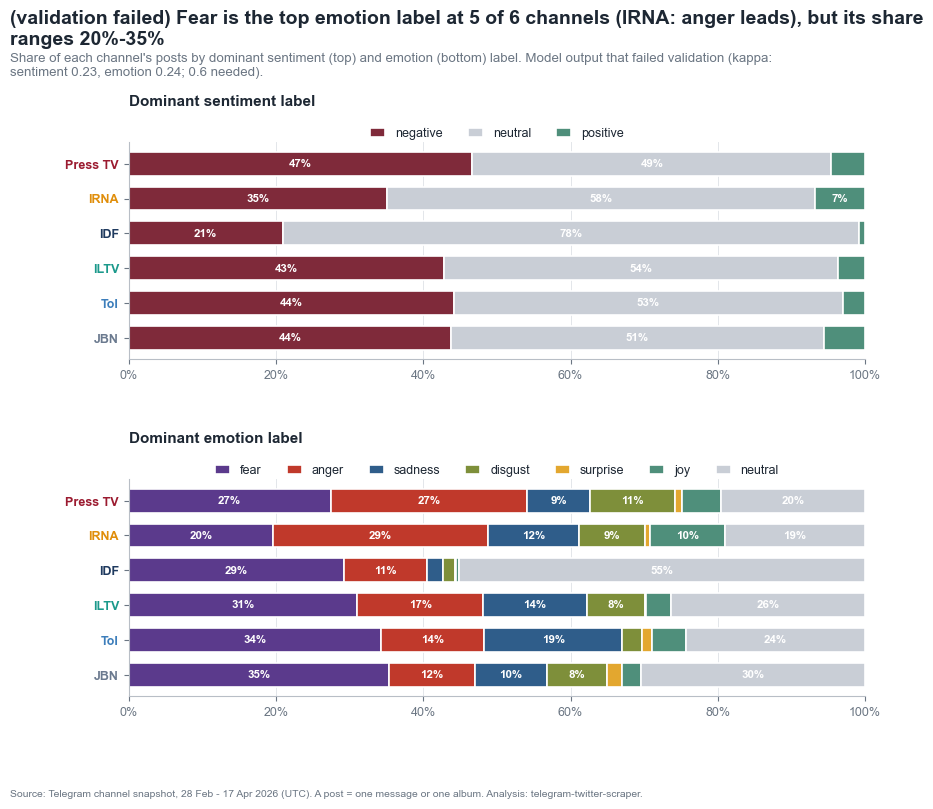

In [11]:
def label_shares(col, order):
    parts = []
    for lab in order:
        t = stats.share_table(scored.assign(_f=scored[col] == lab), "channel_slug", "_f").assign(label=lab)
        parts.append(t)
    long = pd.concat(parts).rename(columns={"share": "share"})
    return long
sent_long = label_shares("dominant_sentiment", ["negative", "neutral", "positive"])
emo_order = ["fear", "anger", "sadness", "disgust", "surprise", "joy", "neutral"]
emo_long = label_shares("dominant_emotion", emo_order)
sent_w = sent_long.pivot(index="channel_slug", columns="label", values="share").reindex(CHANNEL_ORDER)[["negative", "neutral", "positive"]]
emo_w = emo_long.pivot(index="channel_slug", columns="label", values="share").reindex(CHANNEL_ORDER)[emo_order]
display((sent_w * 100).round(1)); display((emo_w * 100).round(1))

fig, axes = plt.subplots(2, 1, figsize=(9.5, 7.2), gridspec_kw={"hspace": 0.55})
viz.stacked_share_bars(axes[0], sent_w, colors={"negative": "#7F2A3A", "neutral": "#C9CED6", "positive": "#4F8F7B"}, label_min=0.06)
axes[0].set_title("Dominant sentiment label", pad=26)
emo_colors = {"fear": "#5B3A8C", "anger": "#C0392B", "sadness": "#2F5D8A", "disgust": "#7E8F3A", "surprise": "#E3A72F", "joy": "#4F8F7B", "neutral": "#C9CED6"}
viz.stacked_share_bars(axes[1], emo_w, colors=emo_colors, label_min=0.06)
axes[1].set_title("Dominant emotion label", pad=26)
fear = emo_w["fear"]
top_emo = emo_w.drop(columns="neutral").idxmax(axis=1)
not_fear = [SHORT_NAMES[s] for s in top_emo.index if top_emo[s] != "fear"]
viz.headline(fig, f"({FLAG}) Fear is the top emotion label at {int((top_emo == 'fear').sum())} of 6 channels ({', '.join(not_fear) or 'none'}: anger leads), but its share ranges {fear.min():.0%}-{fear.max():.0%}",
             "Share of each channel's posts by dominant sentiment (top) and emotion (bottom) label. " + VAL_NOTE + ".", y=1.01)
viz.done(fig, "05_label_shares", pd.concat([sent_long.assign(scale="sentiment"), emo_long.assign(scale="emotion")]))

**Reading the figure (model labels that failed validation; not a finding).** As computed, 47% of Press TV posts are labelled negative against 43-44% at ILTV, ToI and JBN, 35% at IRNA and 21% at the IDF (78% neutral), and positive labels are 1-7% everywhere. For emotion the model's top label is fear at five of six channels (spread 20% at IRNA to 35% at JBN; Press TV 27.4% fear vs 26.7% anger; IRNA's top is anger at 29%; the IDF's neutral at 55%). The second reader does not reproduce this: on the 900 validation posts its most common emotion is joy (25%), then neutral (21%) and fear (20%). So "fear-dominant" is a property of the classifier, not something the data supports.

## 5. "Convergence" by equivalence tests (TOST) on model scores

"The channels sound alike" is a claim of **equivalence**, which a non-significant difference test cannot support. Two one-sided tests (TOST, Welch) check whether each pair's mean sentiment difference lies within ±0.1 on the -1...+1 score (a judgement-call margin: 5% of the scale), Benjamini-Hochberg adjusted over the 15 pairs. This is arithmetic on classifier scores whose validity section 2 has just tested: a pair that is "equivalent" here has equal *model* scores, not necessarily equal tone.

,sample,a,b,pair,mean_diff,ci90_low,ci90_high,p_tost,p_tost_bh,equivalent
0,all posts,presstv,irna-en,Press TV - IRNA,-0.1160,-0.1351,-0.0969,0.9161,1.0000,False
1,all posts,presstv,idfofficial,Press TV - IDF,-0.1932,-0.2089,-0.1776,1.0000,1.0000,False
2,all posts,presstv,iltvnews,Press TV - ILTV,-0.0418,-0.0704,-0.0131,0.0004,0.0016,True
3,all posts,presstv,thetimesofisrael2022,Press TV - ToI,-0.0029,-0.0287,0.0230,0.0000,0.0000,True
4,all posts,presstv,jewishbreakingnewstelegram,Press TV - JBN,-0.0450,-0.0672,-0.0228,0.0000,0.0001,True
5,all posts,irna-en,idfofficial,IRNA - IDF,-0.0772,-0.0991,-0.0554,0.0431,0.0808,False
6,all posts,irna-en,iltvnews,IRNA - ILTV,0.0743,0.0418,0.1067,0.0958,0.1597,False
7,all posts,irna-en,thetimesofisrael2022,IRNA - ToI,0.1132,0.0832,0.1431,0.7650,1.0000,False
8,all posts,irna-en,jewishbreakingnewstelegram,IRNA - JBN,0.0710,0.0441,0.0979,0.0380,0.0808,False
9,all posts,idfofficial,iltvnews,IDF - ILTV,0.1515,0.1209,0.1820,0.9972,1.0000,False


6 of 15 channel pairs are statistically equivalent within +/-0.1


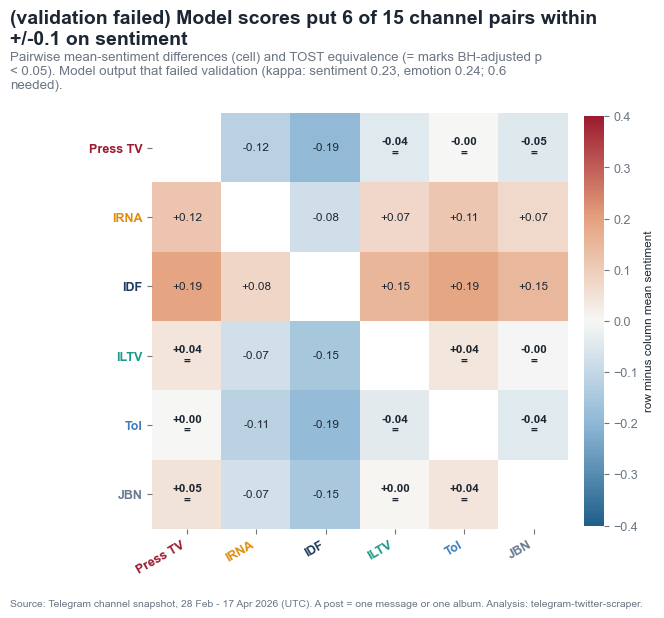

In [12]:
from itertools import combinations
MARGIN = 0.1
def tost_table(frame, label):
    rows = []
    for a, b in combinations(CHANNEL_ORDER, 2):
        r = stats.tost_equivalence(frame.loc[frame["channel_slug"] == a, "sentiment_score"], frame.loc[frame["channel_slug"] == b, "sentiment_score"], margin=MARGIN)
        rows.append({"sample": label, "a": a, "b": b, "pair": f"{SHORT_NAMES[a]} - {SHORT_NAMES[b]}", **{k: r[k] for k in ("mean_diff", "ci90_low", "ci90_high", "p_tost")}})
    out = pd.DataFrame(rows)
    out["p_tost_bh"] = stats.bh_adjust(out["p_tost"])
    out["equivalent"] = out["p_tost_bh"] < 0.05
    return out
tost = tost_table(scored, "all posts")
display(tost.round(4))
print(f"{int(tost['equivalent'].sum())} of {len(tost)} channel pairs are statistically equivalent within +/-{MARGIN}")

diff = pd.DataFrame(index=CHANNEL_ORDER, columns=CHANNEL_ORDER, dtype=float)
eq = pd.DataFrame(False, index=CHANNEL_ORDER, columns=CHANNEL_ORDER)
for r in tost.itertuples():
    diff.loc[r.a, r.b] = r.mean_diff; diff.loc[r.b, r.a] = -r.mean_diff
    eq.loc[r.a, r.b] = eq.loc[r.b, r.a] = r.equivalent
fig, ax = plt.subplots(figsize=(6.6, 5.4))
shown = diff.rename(index=SHORT_NAMES, columns=SHORT_NAMES)
im = ax.imshow(shown.to_numpy(dtype=float), cmap=viz.DIV_CMAP, vmin=-0.4, vmax=0.4)
ax.set_xticks(range(6)); ax.set_xticklabels(shown.columns, rotation=30, ha="right"); ax.set_yticks(range(6)); ax.set_yticklabels(shown.index)
for i, a in enumerate(CHANNEL_ORDER):
    for j, b in enumerate(CHANNEL_ORDER):
        if i == j: continue
        ax.text(j, i, f"{diff.loc[a, b]:+.2f}" + ("\n=" if eq.loc[a, b] else ""), ha="center", va="center", fontsize=8.5, color=viz.INK, fontweight="bold" if eq.loc[a, b] else "normal")
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03); cb.set_label("row minus column mean sentiment", fontsize=8.5); cb.outline.set_visible(False)
viz.color_channel_ticklabels(ax); viz.color_channel_ticklabels(ax, axis="x")
viz.headline(fig, f"({FLAG}) Model scores put {int(tost['equivalent'].sum())} of 15 channel pairs within +/-0.1 on sentiment",
             "Pairwise mean-sentiment differences (cell) and TOST equivalence (= marks BH-adjusted p < 0.05). " + VAL_NOTE + ".", y=1.0, wrap=70)
viz.done(fig, "05_tost_matrix", tost)

**Reading the figure (equivalence of model scores; not a finding).** With a ±0.1 margin, 6 of 15 pairs pass the equivalence test on the model's scores: Press TV, ILTV, ToI and JBN are mutually equivalent (largest gap 0.05), while IRNA and the IDF are not equivalent to anything (gaps 0.07-0.19; IRNA vs IDF is 0.08 and just misses at adjusted p = 0.08). This says the *classifier* gives these four channels equal average scores; section 2 shows it is blind to exactly the framing that differs between channels. For example Press TV and ToI have identical model means (-0.35) but the coder labels 33% of the Press TV validation posts positive against 15% of ToI's. A statistically equivalent score is therefore not evidence of equivalent tone, and "partial convergence" must not be reported.

### Over time, and without repeated texts

The same TOST in the first ten and last ten days, and after dropping exact-duplicate posts (the IDF repeats alert templates).

,pairs,equivalent,max_abs_diff
sample,,,
28 Feb-9 Mar,15.0,0.0,0.217459
8-17 Apr,15.0,0.0,0.333767
unique texts only,15.0,11.0,0.112138
all posts,15.0,6.0,0.193230


range of channel means: early 0.217 | late 0.334


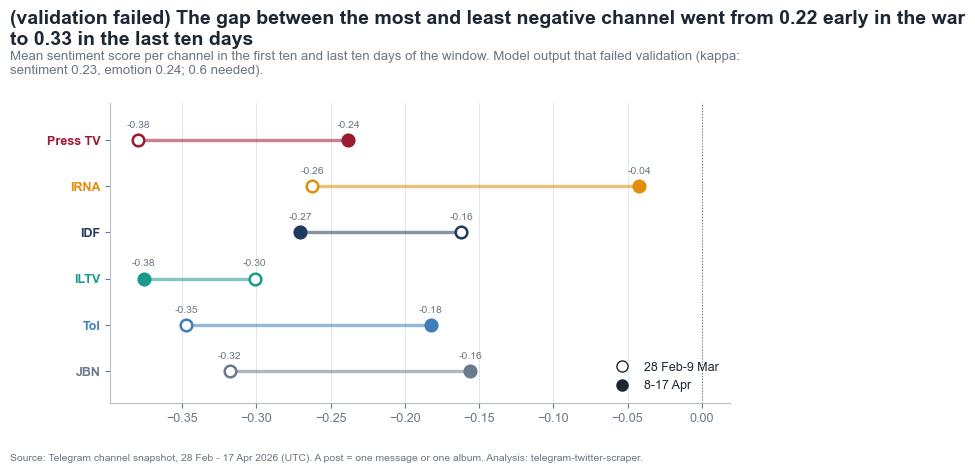

In [13]:
# Does the picture change over time? Same TOST in the first and last ten days, and without exact-duplicate posts.
early = scored[scored["timestamp"] < pd.Timestamp("2026-03-10", tz="UTC")]
late = scored[scored["timestamp"] >= pd.Timestamp("2026-04-08", tz="UTC")]
dedup = scored.drop_duplicates(subset="clean_text")
robust = pd.concat([tost_table(early, "28 Feb-9 Mar"), tost_table(late, "8-17 Apr"), tost_table(dedup, "unique texts only")])
summary = robust.groupby("sample").agg(pairs=("pair", "size"), equivalent=("equivalent", "sum"), max_abs_diff=("mean_diff", lambda s: s.abs().max()))
summary.loc["all posts"] = [len(tost), int(tost["equivalent"].sum()), tost["mean_diff"].abs().max()]
display(summary)
means = pd.DataFrame({
    "early_28Feb_9Mar": early.groupby("channel_slug")["sentiment_score"].mean(),
    "late_8_17Apr": late.groupby("channel_slug")["sentiment_score"].mean(),
}).reindex(CHANNEL_ORDER)
print("range of channel means: early", round(means["early_28Feb_9Mar"].max() - means["early_28Feb_9Mar"].min(), 3), "| late", round(means["late_8_17Apr"].max() - means["late_8_17Apr"].min(), 3))
fig, ax = plt.subplots(figsize=(8, 3.9))
plot_df = means.reset_index().assign(channel=lambda d: d["channel_slug"].map(SHORT_NAMES))
viz.dumbbell(ax, plot_df, label_col="channel", start_col="early_28Feb_9Mar", end_col="late_8_17Apr", start_label="28 Feb-9 Mar", end_label="8-17 Apr", value_fmt="{:+.2f}")
ax.axvline(0, color=viz.MUTED, lw=0.8, ls=":")
rng_e, rng_l = means["early_28Feb_9Mar"].max() - means["early_28Feb_9Mar"].min(), means["late_8_17Apr"].max() - means["late_8_17Apr"].min()
viz.headline(fig, f"({FLAG}) The gap between the most and least negative channel went from {rng_e:.2f} early in the war to {rng_l:.2f} in the last ten days",
             "Mean sentiment score per channel in the first ten and last ten days of the window. " + VAL_NOTE + ".")
viz.done(fig, "05_sentiment_early_late", plot_df.drop(columns="channel"))

**Reading the figure and table (model scores that failed validation; not findings).** Two robustness checks on the model scores:

- *Over time.* In the first ten days (28 Feb-9 Mar) and the last ten (8-17 Apr) no pair is provably equivalent (intervals are wider with fewer posts) and the gap between the most and least negative channel grows from 0.22 to 0.33: Press TV, IRNA, ToI and JBN all score less negative (IRNA the most, -0.26 to -0.04), while the IDF (-0.16 to -0.27) and ILTV (-0.30 to -0.38) score more negative. Given the validation result these movements cannot be read as changes of tone; they may equally reflect changes in what kinds of posts the channels published.
- *Without repeated texts.* Dropping exact-duplicate posts (the IDF's templates mostly) leaves 11 of 15 pairs equivalent and the largest gap at 0.11, so part of the IDF's apparent difference is its alert templates, a text-composition effect and not a tone effect.

## 6. Model scores around the verified events

Three-day rolling mean of daily mean sentiment per channel; days with fewer than 3 scored posts are left blank.

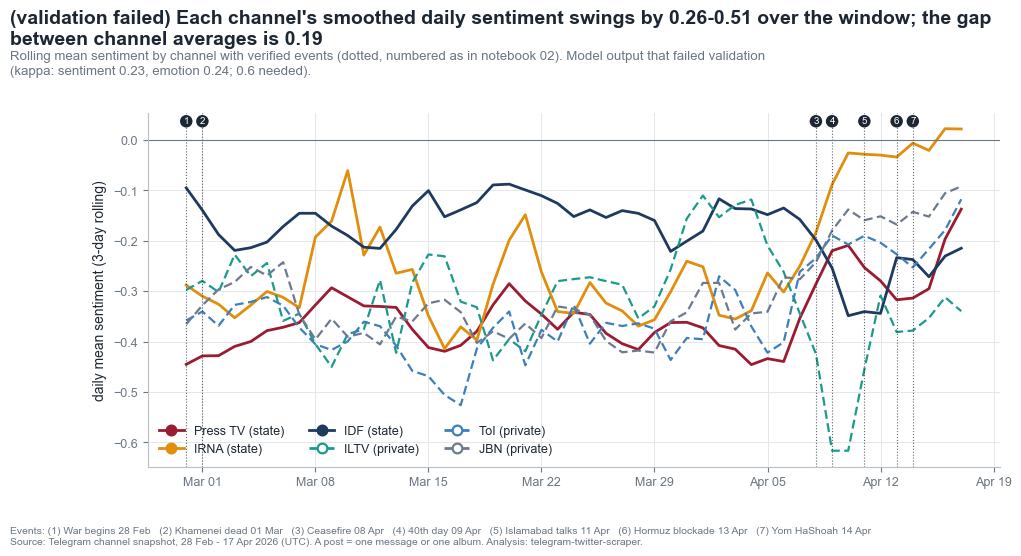

PosixPath('/Users/lfpmb/Documents/telegram-twitter-scraper/docs/study/interactive/05_tone_timeline.html')

In [14]:
dm = scored.groupby(["date", "channel_slug"])["sentiment_score"].agg(["mean", "size"]).reset_index()
wide = dm.pivot(index="date", columns="channel_slug", values="mean").reindex(columns=CHANNEL_ORDER)
n_day = dm.pivot(index="date", columns="channel_slug", values="size").reindex(columns=CHANNEL_ORDER)
wide = wide.where(n_day >= 3)
smooth = wide.rolling(3, center=True, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(11, 4.6))
for slug in CHANNEL_ORDER:
    st = viz.style(slug)
    ax.plot(smooth.index, smooth[slug], color=st["color"], ls=st["linestyle"], lw=2.0 if CHANNELS[slug]["ownership"] == "state" else 1.6)
for i, e in enumerate(events, start=1):
    x = pd.Timestamp(e["date"], tz="UTC"); ax.axvline(x, color=viz.INK, lw=0.8, ls=":", alpha=0.7)
    ax.annotate(str(i), (x, 1.0), xycoords=("data", "axes fraction"), xytext=(0, -3), textcoords="offset points", ha="center", va="top", fontsize=7, color="white", bbox={"boxstyle": "circle,pad=0.18", "fc": viz.INK, "ec": "none"})
ax.axhline(0, color=viz.MUTED, lw=0.8)
viz.channel_legend(ax, ncol=3, loc="lower left")
ax.set_ylabel("daily mean sentiment (3-day rolling)")
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.SU)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
swing = (smooth.max() - smooth.min()).sort_values()
gap = sent["mean"].max() - sent["mean"].min()
viz.headline(fig, f"({FLAG}) Each channel's smoothed daily sentiment swings by {swing.iloc[0]:.2f}-{swing.iloc[-1]:.2f} over the window; the gap between channel averages is {gap:.2f}",
             "Rolling mean sentiment by channel with verified events (dotted, numbered as in notebook 02). " + VAL_NOTE + ".")
viz.done(fig, "05_tone_timeline", wide.reset_index().melt(id_vars="date", var_name="channel_slug", value_name="mean_sentiment").dropna(), note=viz.event_key(events))
viz.save(viz.plotly_lines(smooth, title="Daily mean sentiment per channel", subtitle="3-day rolling mean. " + VAL_NOTE, events=events, ylabel="mean sentiment"), "05_tone_timeline")

**Reading the figure (model scores that failed validation; not a finding).** Each channel's smoothed daily mean moves over a range comparable with, or larger than, the entire spread between channel averages (see the title). After the 8 April ceasefire (3) IRNA's rolling mean climbs from about -0.3 to about 0 by 16-17 April while ILTV, on fewer than ten posts a day, dips to about -0.6 around 9-10 April; at the war's start (1-2) the IDF, ILTV and JBN begin less negative than Press TV (about -0.45). No single event produces a common jump in all channels. Because the scores failed validation these are movements of a classifier output, not evidence of changes in tone around events.

In [15]:
_ = study.record_findings("05_tone", {
    "model_note": "cardiffnlp/twitter-roberta-base-sentiment-latest + j-hartmann/emotion-english-distilroberta-base; " + ("did not pass validation (kappa < 0.6)" if agreement is not None and not usable else "see validation"),
    "sentiment_mean_ci": sent.drop(columns="channel"),
    "sentiment_label_shares": sent_long,
    "emotion_label_shares": emo_long,
    "tost_margin": MARGIN,
    "tost_pairs": tost.drop(columns=["a", "b"]),
    "tost_equivalent_pairs": int(tost["equivalent"].sum()),
    "tost_robustness": summary.reset_index(),
    "channel_mean_range": {"early": float(rng_e), "late": float(rng_l)},
    "validation": {"sheet_rows": int(len(sheet_df)), "coded_file_present": bool(CODED.exists()), "usable_labels": usable,
                   "second_coder": "LLM (three Claude Sonnet sub-agents, 300 posts each); not a human and not ground truth",
                   "status": "pending second coder (LLM)" if agreement is None else "scored",
                   "kappa": None if agreement is None else agreement.set_index("label")["kappa"].to_dict(),
                   "agreement": None if agreement is None else agreement.set_index("label")["agreement"].to_dict(),
                   "kappa_by_channel": None if agreement is None else kap_ch[["channel_slug", "scale", "kappa", "n"]],
                   "label_shares_by_rater": None if agreement is None else val_shares,
                   "overall_label_shares": None if agreement is None else overall,
                   "confusion_row_normalised": None if agreement is None else pd.DataFrame(tidy)},
})

## What this means for the article

- **Report no tone comparison from the classifiers.** Neither label passes kappa >= 0.6 (sentiment 0.23, emotion 0.24; per-channel 0.35 at best). That rules out the TOST "partial convergence" among Press TV, ILTV, ToI and JBN, "fear tops five of six channels", the early-vs-late widening, and every event timeline in this notebook.
- **The reportable result is the disagreement, worded with its limits**: "off-the-shelf sentiment and emotion classifiers agreed with an independent second reader on only 49% (sentiment) and 37% (emotion) of 900 blind posts; the classifiers call 4% of posts positive, the reader 26%, the gap being largest for military and state-media communiqués (IDF 45%, Press TV 33% reader-positive)". State that the second reader is an LLM that read mostly the first 250-300 characters, is not ground truth, and that its "positive" includes triumphal or defiant claims by codebook choice.
- **Do not turn the reader's labels into findings either.** One LLM coder, 150 posts per channel (about ±8 points) and no human check make the per-channel positive shares hypotheses. They do suggest a better lens than generic sentiment: triumphalist or success-claiming framing in state and military communiqués.
- **If tone matters to the article**, the sheet (`data/validation/coding_sheet.csv`) can be re-coded by humans, or a war-specific stance or triumphalism scheme can be validated first. Until then drop the first-pass "fear-dominant convergence" sentence entirely.
- **Say the IDF's numbers are mostly templates and communiqués** (nearly half its posts are exact repeats, kappa about 0).